In [35]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()
df.price.mean()

np.float64(89.24380943923661)

In [23]:
# 1.1 Generate a frequency table for the product category.
cat_freq_table = df.category.value_counts()
cat_freq_table
#cat_freq_table


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [25]:
# 1.2 Which are the top 5 most listed product categories?

cat_top5 = df.category.value_counts()[:5]

cat_top5


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

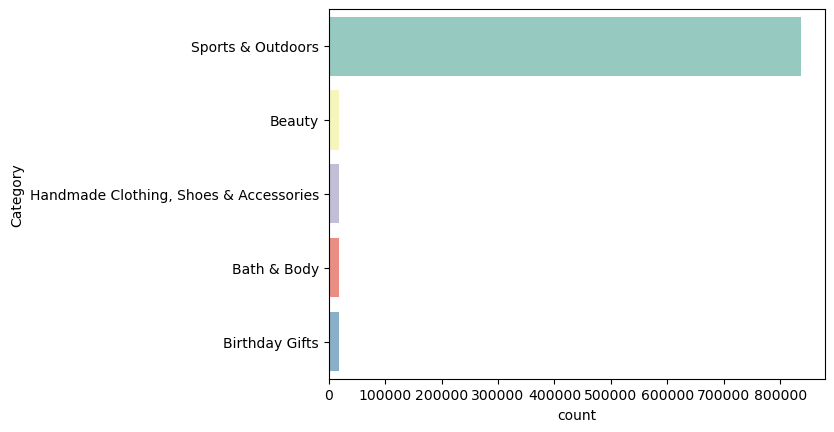

np.float64(89.24380943923661)

In [26]:
# 2.1 Display the distribution of products across different categories using a bar chart.
# If you face problems understanding the chart, do it for a subset of top categories.
fig, axes = plt.subplots()
sns.barplot(x = cat_top5.values, y = cat_top5.index,  palette = "Set3", hue = cat_top5.index, legend = False, ax = axes)
axes.set_xlabel("count")
axes.set_ylabel("Category")
plt.show()


In [21]:
#Part 2:
#1.1. Calculate the mean, median, and mode for the price of products
print(df.price.describe())
print("mean_value = ",  round(df.price.mean(), 2))
print("median_value = ",  df.price.median())
print("mode = ",  df.price.mode()[0])

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64
mean_value =  89.24
median_value =  19.09
mode =  9.99


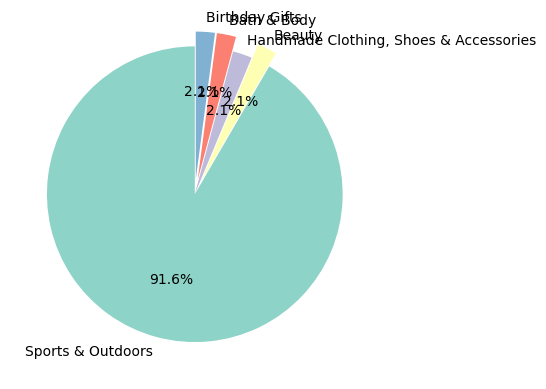

np.float64(89.24380943923661)

In [27]:
For a subset of top categories, visualize their 
#proportions using a pie chart. Does any category dominate the listings?
plt.pie(x= cat_top5.values, labels =cat_top5.index, autopct = '%1.1f%%', colors = sns.color_palette('Set3'), startangle = 90, explode = (0, 0.1, 0.0, 0.1, 0.1))
plt.show()


# ANSWER 2.2 
# Yes, category Sports & Outdoors dominates

#1.2 What's the average price point of products listed? How does this compare with the most common price point (mode)?
# The average value is much highr that the most freqent value (mode): 89.24 >>9.99


In [29]:
#2.1Determine the variance, standard deviation, range, and interquartile range for product price.
print("variance = ",  round(df.price.var(), 2))
print("standard deviation = ",  round(df.price.std(),2))
print("range = ", round(df.price.max() - df.price.min(), 2))
print("max_price = ", df.price.max())
print("min_price = ", df.price.min())
print("IQR = ",  round(df.price.quantile(0.75) - df.price.quantile(0.25),2))

variance =  119445.49
standard deviation =  345.61
range =  100000.0
max_price =  100000.0
min_price =  0.0
IQR =  36.0


#2.2 How varied are the product prices? Are there any indicators of a significant spread in prices?
# prices are very largely spread


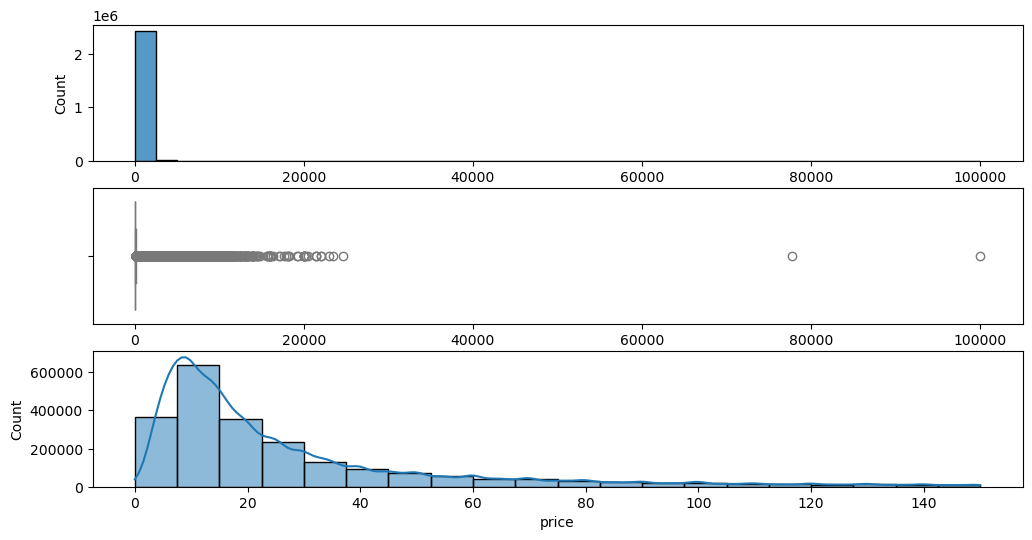

In [44]:
#3.1 Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices.
#If its hard to read these diagrams, think why this is, and explain how it could be solved..
fig, axes = plt.subplots(3, 1, figsize = (12,6))
sns.histplot(data = df, x = df.price,  bins = 40, ax = axes[0])
sns.boxplot(data = df, x = df.price, color="lightblue", ax = axes[1])
#plt.show()#Histogram is difficult to read, because the range of prices is very large. Can be solved by
#1. consider only the 90% of data r creating boxchart to see outliers
condition = df.price <= df.price.quantile(0.9)
df_qt= df[condition]
sns.histplot(data = df_qt, x = df_qt["price"], bins = 20, kde =True, ax = axes[2])
plt.show()
#plot a boxchart


#3. 2 Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.
# ANswer: yes, there are many outliers

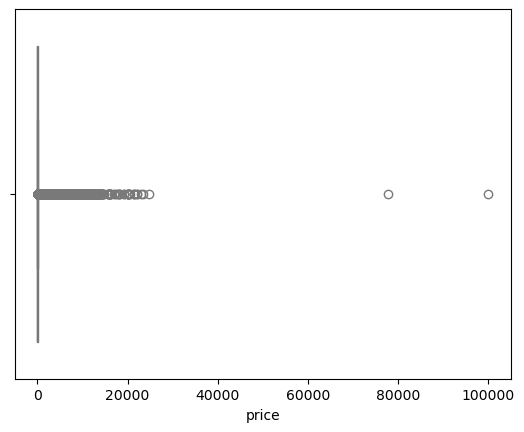

In [47]:
sns.boxplot(data = df, x = df.price, color="lightblue")
plt.show()

In [48]:
# PART3
# 3.1.1 Calculate the mean, median, and mode for the rating of products.


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [69]:
### df.stars.isnull().any()
print("mean_value = ",  df.stars.mean(), 2)
print("median_value = ",  df.stars.median())
print("mode = ",  df.stars.mode()[0])
df.shape

mean_value =  2.152836472966066 2
median_value =  0.0
mode =  0.0


(2443651, 9)

In [68]:
#3.1.2 How do customers generally rate products? Is there a common trend? ==>The avecrage value is quite low (under the standard average 50%); and the mode is almost 0, means that the most frequent rating is around 0
#3.2.1 Determine the variance, standard deviation, and interquartile range for product rating.
print("variance = ",  round(df.stars.var(), 2))
print("standard deviation = ",  round(df.stars.std(),2))
print("range = ", round(df.stars.max() - df.stars.min(), 2))
print("max_ = ", df.stars.max())
print("min_ = ", df.stars.min())
print("IQR = ",  df.stars.quantile(0.75) - df.stars.quantile(0.25))
print("Q.25 = ",  df.stars.quantile(0.25))
print("Q75 = ",  df.stars.quantile(0.75))

variance =  4.82
standard deviation =  2.19
range =  5.0
max_ =  5.0
min_ =  0.0
IQR =  4.4
Q.25 =  0.0
Q75 =  4.4


#3.2.2 Are the ratings consistent, or is there a wide variation in customer feedback?
# ANSWER: 
most of the ratings are concentrated in the middle 50%: IQR = 4.4

In [72]:
#3.3.1 Calculate the skewness and kurtosis for the rating column.
print("swew: ", df.stars.skew())

print("Kurtosis: ", df.stars.kurtosis())

#3.3.2 Are the ratings normally distributed, or do they lean towards higher or lower values?


swew:  0.08120735761080881
Kurtosis:  -1.9260061280432994


# ANSWER: 3.3.1
skewness is 0.081: symetrical distribution, with a light lean towards higher values, with light tails (negative kurtosis)

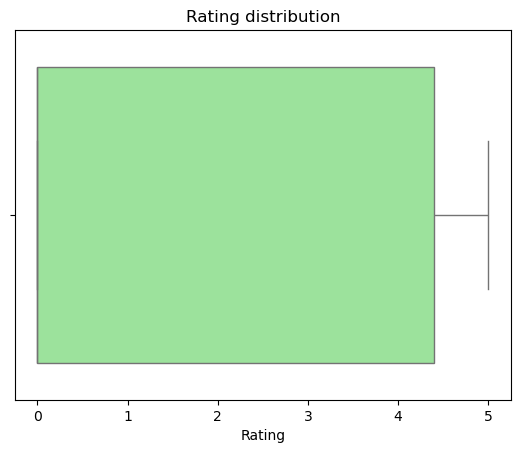

In [75]:
# 4. 1. Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
sns.boxplot(data = df, x = 'stars', color = 'lightgreen')
plt.xlabel("Rating")
plt.title("Rating distribution")
plt.show()


# ANSWER4.1 
Most of ratings fall between Q1 & Q3